# 01 – Keşifsel Veri Analizi (EDA)

**Veri:** UCI Individual Household Electric Power Consumption (dakikalık → saatlik).
**Kapsam:** README §4.2 EDA kontrol listesi.

**Kapsam kuralı (veri sızıntısı):**
- *Eksik veri analizi* ve *bölme şeması* **tüm dönem** üzerinde yapılır: yalnızca verinin *nerede eksik olduğuna* bakar, tüketim değerlerine bakmaz. Ön işleme tüm kümelere uygulandığı için bu bilgi gereklidir.
- Tüketim değerlerine dayanan tüm analizler (dağılım, profiller, korelasyon, ACF, olağandışı günler) **yalnızca eğitim kümesinde** yapılır. Bu analizler log dönüşümü, lookback ve öznitelik seçimi gibi kararları besler; test kümesi bu kararlara karışmamalıdır (CLAUDE.md kural 5).
- Doldurulmuş (`is_imputed=1`) saatler istatistiklere katılmaz; yalnız ACF'de seri kesintisiz olmak zorunda olduğu için dahildir.

Yükleme ve ön işleme kodu burada **yeniden yazılmaz**: `src/data/load.py`, `src/data/preprocess.py`, `src/data/split.py` fonksiyonları kullanılır.

In [1]:
import gc
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import acf

# Notebook notebooks/ klasöründen çalışır; proje kökünü import yoluna ekliyoruz.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data.load import load_config, load_raw_data
from src.data.preprocess import preprocess
from src.data.split import chronological_split

config = load_config()
TARGET = config["preprocess"]["target"]
FIG_DIR = ROOT / config["paths"]["figures_dir"]
FIG_DIR.mkdir(parents=True, exist_ok=True)

DAY_NAMES = ["Pzt", "Sal", "Çar", "Per", "Cum", "Cmt", "Paz"]
MONTH_NAMES = ["Oca", "Şub", "Mar", "Nis", "May", "Haz", "Tem", "Ağu", "Eyl", "Eki", "Kas", "Ara"]

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})


def save_fig(fig, name):
    """Figürü results/figures/eda_<name>.png olarak 200 dpi ile kaydeder."""
    path = FIG_DIR / f"eda_{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print("Kaydedildi:", path.relative_to(ROOT))

## 1. Ham (dakikalık) veri: boyut, tarih aralığı, örnekleme, tekrarlar

In [2]:
raw = load_raw_data()                 # src/data/load.py: '?' -> NaN, datetime indeks, sıralı
raw = raw.astype("float32")           # bellek: float64 -> float32 (yarıya iner)

print(f"Satır sayısı: {len(raw):,}")
print("Başlangıç:", raw.index.min(), "| Bitiş:", raw.index.max())
print(f"Bellek (float32): {raw.memory_usage(deep=True).sum() / 1e6:.1f} MB")

# Örnekleme tutarlılığı: ardışık zaman damgaları arasındaki fark hep 1 dakika mı?
step_counts = raw.index.to_series().diff().value_counts()
print("\nArdışık kayıtlar arası fark (en sık 5):")
print(step_counts.head().to_string())

expected_minutes = pd.date_range(raw.index.min(), raw.index.max(), freq="1min")
print(f"\nBeklenen dakika sayısı: {len(expected_minutes):,}")
print(f"Hiç satırı olmayan dakika: {len(expected_minutes) - len(raw):,}")
# load_raw_data tekrarlı zaman damgasında hata verir; yine de açıkça sayıyoruz.
print("Tekrarlı zaman damgası:", int(raw.index.duplicated().sum()))

Satır sayısı: 2,075,259
Başlangıç: 2006-12-16 17:24:00 | Bitiş: 2010-11-26 21:02:00
Bellek (float32): 74.7 MB

Ardışık kayıtlar arası fark (en sık 5):
datetime
0 days 00:01:00    2075258

Beklenen dakika sayısı: 2,075,259
Hiç satırı olmayan dakika: 0
Tekrarlı zaman damgası: 0


In [3]:
# Kaydı olmayan dakikalar da NaN satır olarak eklenir -> tüm eksikler görünür olur.
minute = raw.asfreq("1min")
minute.index.name = "datetime"

missing_table = pd.DataFrame({
    "eksik_dakika": minute.isna().sum(),
    "eksik_oran_%": (minute.isna().mean() * 100).round(3),
})
print(missing_table.to_string())

# Sütunlar aynı dakikalarda mı eksik? (Öyleyse eksiklik satır düzeyinde: ölçüm hiç yok.)
same_rows = (minute.isna().any(axis=1) == minute[TARGET].isna()).all()
print("\nTüm sütunlar aynı dakikalarda mı eksik?", bool(same_rows))

                       eksik_dakika  eksik_oran_%
Global_active_power           25979         1.252
Global_reactive_power         25979         1.252
Voltage                       25979         1.252
Global_intensity              25979         1.252
Sub_metering_1                25979         1.252
Sub_metering_2                25979         1.252
Sub_metering_3                25979         1.252

Tüm sütunlar aynı dakikalarda mı eksik? True


## 2. Eksik veri: kesintiler, süre dağılımı, en uzun 5 kesinti

In [4]:
is_missing = minute[TARGET].isna()

# Ardışık eksik dakikaları tek bir "kesinti" sayıyoruz:
# eksik/var durumu her değiştiğinde yeni bir grup numarası başlar.
run_id = (is_missing != is_missing.shift()).cumsum()
outages = (
    pd.DataFrame({"time": is_missing.index[is_missing], "run": run_id[is_missing].to_numpy()})
    .groupby("run")["time"]
    .agg(start="min", end="max", minutes="size")
    .reset_index(drop=True)
)
outages["hours"] = (outages["minutes"] / 60).round(2)

print(f"Kesinti sayısı: {len(outages):,}")
print(f"Toplam eksik dakika: {outages['minutes'].sum():,}")
print(f"Medyan kesinti süresi: {outages['minutes'].median():.0f} dk")

bins = [0, 1, 10, 60, 180, 1440, np.inf]
labels = ["1 dk", "2–10 dk", "11–60 dk", "1–3 saat", "3–24 saat", "> 24 saat"]
outages["duration_class"] = pd.cut(outages["minutes"], bins=bins, labels=labels)
duration_table = outages.groupby("duration_class", observed=False)["minutes"].agg(
    kesinti_sayisi="size", toplam_eksik_dakika="sum"
)
duration_table["eksik_dakika_payi_%"] = (
    duration_table["toplam_eksik_dakika"] / outages["minutes"].sum() * 100
).round(1)
print("\nSüre sınıflarına göre kesintiler:")
print(duration_table.to_string())

top5 = outages.nlargest(5, "minutes")[["start", "end", "minutes", "hours"]].copy()
top5["days"] = (top5["minutes"] / 1440).round(2)
top5.columns = ["başlangıç (ilk eksik dk)", "bitiş (son eksik dk)", "dakika", "saat", "gün"]
print("\nEn uzun 5 kesinti:")
print(top5.to_string(index=False))

Kesinti sayısı: 71
Toplam eksik dakika: 25,979
Medyan kesinti süresi: 1 dk



Süre sınıflarına göre kesintiler:
                kesinti_sayisi  toplam_eksik_dakika  eksik_dakika_payi_%
duration_class                                                          
1 dk                        38                   38                  0.1
2–10 dk                     18                   44                  0.2
11–60 dk                     6                  206                  0.8
1–3 saat                     2                  153                  0.6
3–24 saat                    1                  891                  3.4
> 24 saat                    6                24647                 94.9

En uzun 5 kesinti:
başlangıç (ilk eksik dk) bitiş (son eksik dk)  dakika   saat  gün
     2010-08-17 21:02:00  2010-08-22 21:27:00    7226 120.43 5.02
     2010-09-25 03:56:00  2010-09-28 19:12:00    5237  87.28 3.64
     2007-04-28 00:21:00  2007-04-30 14:23:00    3723  62.05 2.59
     2009-06-13 00:30:00  2009-06-15 07:34:00    3305  55.08 2.30
     2010-01-12 14:53:00  2010-

Kaydedildi: results\figures\eda_outage_durations.png


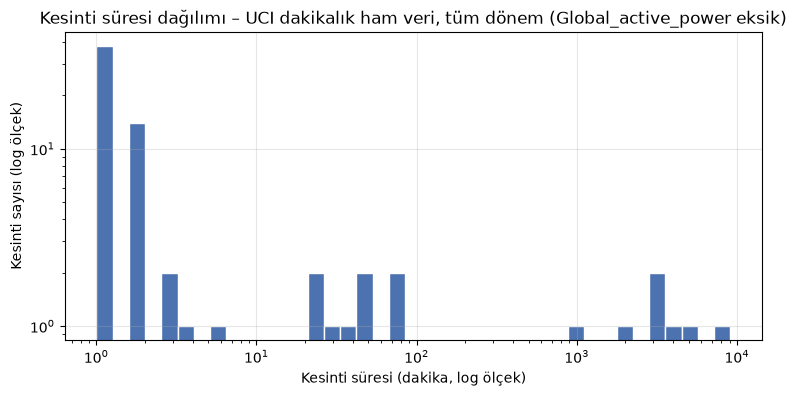

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
log_bins = np.logspace(0, np.log10(outages["minutes"].max()) + 0.1, 40)
ax.hist(outages["minutes"], bins=log_bins, color="#4C72B0", edgecolor="white")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Kesinti süresi (dakika, log ölçek)")
ax.set_ylabel("Kesinti sayısı (log ölçek)")
ax.set_title("Kesinti süresi dağılımı – UCI dakikalık ham veri, tüm dönem (Global_active_power eksik)")
save_fig(fig, "outage_durations")
plt.show()

**Gözlem:** Toplam 71 kesinti var ve bunların 38'i yalnızca 1 dakika sürüyor (medyan 1 dk). Buna karşılık 25.979 eksik dakikanın %94,9'u, 24 saatten uzun 6 kesintiden geliyor. Yani kesintilerin sayıca çoğu çok kısa, eksik sürenin neredeyse tamamı ise birkaç uzun kesintide.

Kaydedildi: results\figures\eda_missing_map.png


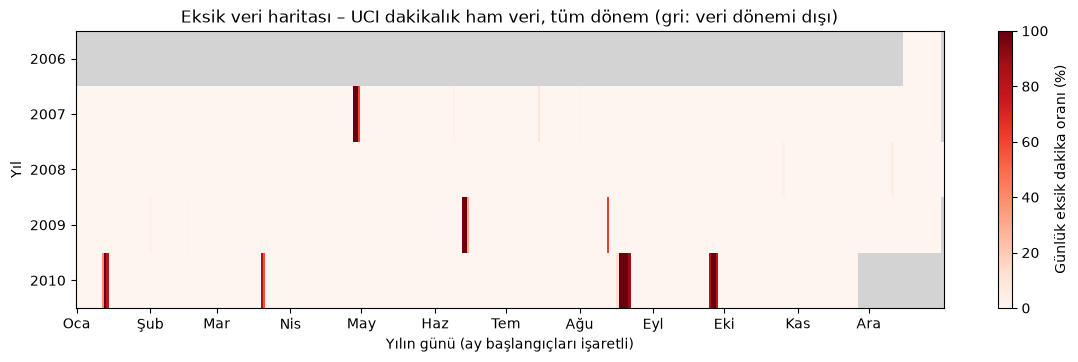

En az bir eksik dakikası olan gün: 82 / 1442
Tamamen eksik gün: 9


In [6]:
# Günlük eksik dakika oranı -> yıl × yılın günü takvim haritası
daily_missing_pct = is_missing.resample("1D").mean() * 100
calendar = (
    pd.DataFrame({
        "year": daily_missing_pct.index.year,
        "day_of_year": daily_missing_pct.index.dayofyear,
        "pct": daily_missing_pct.to_numpy(),
    })
    .pivot(index="year", columns="day_of_year", values="pct")
)

cmap = plt.get_cmap("Reds").copy()
cmap.set_bad("lightgrey")             # veri dönemi dışındaki günler gri
fig, ax = plt.subplots(figsize=(14, 3.6))
im = ax.imshow(
    np.ma.masked_invalid(calendar.to_numpy()), aspect="auto", cmap=cmap,
    vmin=0, vmax=100, interpolation="nearest",
    extent=[0.5, calendar.shape[1] + 0.5, len(calendar) - 0.5, -0.5],
)
ax.set_yticks(range(len(calendar)), calendar.index)
month_starts = pd.date_range("2001-01-01", periods=12, freq="MS").dayofyear
ax.set_xticks(month_starts, MONTH_NAMES)
ax.grid(False)
ax.set_xlabel("Yılın günü (ay başlangıçları işaretli)")
ax.set_ylabel("Yıl")
ax.set_title("Eksik veri haritası – UCI dakikalık ham veri, tüm dönem (gri: veri dönemi dışı)")
fig.colorbar(im, ax=ax, label="Günlük eksik dakika oranı (%)")
save_fig(fig, "missing_map")
plt.show()

days_with_missing = (daily_missing_pct > 0).sum()
print(f"En az bir eksik dakikası olan gün: {days_with_missing} / {daily_missing_pct.notna().sum()}")
print(f"Tamamen eksik gün: {(daily_missing_pct == 100).sum()}")

**Gözlem:** Eksik dakikalar birkaç koyu dikey şeritte toplanıyor: 2007 Nisan sonu, 2009 Haziran ortası ve Ağustos'u, 2010'da Ocak, Mart, Ağustos ve Eylül sonu. 1.442 günün 82'sinde en az bir eksik dakika var, 9 gün tamamen eksik. Tüm sütunlar aynı dakikalarda eksik ve hiç satırı olmayan dakika yok (eksikler '?' işaretli satırlar). En uzun kesinti (2010-08-17 → 2010-08-22, 5,02 gün) test dönemine düşüyor.

## 3. Saatlik veri ve kronolojik bölme

`preprocess()` dakikalık veriyi saatliğe indirger ve eksik saatleri doldurur (README §4.3).
Dakikalık veriyle işimiz bittiği için bellekten siliyoruz.

In [7]:
hourly = preprocess(raw, config)      # src/data/preprocess.py
del raw, minute, is_missing, run_id   # dakikalık veriyle iş bitti -> belleği boşalt
gc.collect()

float_cols = hourly.select_dtypes("float64").columns
hourly[float_cols] = hourly[float_cols].astype("float32")

print(f"Saatlik satır: {len(hourly):,} | sütun: {hourly.shape[1]}")
print("Başlangıç:", hourly.index.min(), "| Bitiş:", hourly.index.max())
print(f"Doldurulan (is_imputed=1) saat: {int(hourly['is_imputed'].sum())} "
      f"(%{hourly['is_imputed'].mean() * 100:.2f})")
print("Kalan NaN:", int(hourly.isna().sum().sum()))

Saatlik satır: 34,589 | sütun: 17
Başlangıç: 2006-12-16 17:00:00 | Bitiş: 2010-11-26 21:00:00
Doldurulan (is_imputed=1) saat: 432 (%1.25)
Kalan NaN: 0


In [8]:
splits = chronological_split(hourly, config)   # tarihler configs/config.yaml'dan

split_table = pd.DataFrame([
    {
        "küme": name,
        "başlangıç": part.index.min(),
        "bitiş": part.index.max(),
        "saat": len(part),
        "oran_%": round(len(part) / len(hourly) * 100, 1),
        "doldurulan_saat": int(part["is_imputed"].sum()),
    }
    for name, part in splits.items()
])
print(split_table.to_string(index=False))
print("\nKümelerin toplamı = tüm saatler?", split_table["saat"].sum() == len(hourly))

 küme           başlangıç               bitiş  saat  oran_%  doldurulan_saat
train 2006-12-16 17:00:00 2009-09-30 23:00:00 24463    70.7              138
  val 2009-10-01 00:00:00 2010-03-31 23:00:00  4368    12.6               86
 test 2010-04-01 00:00:00 2010-11-26 21:00:00  5758    16.6              208

Kümelerin toplamı = tüm saatler? True


Kaydedildi:

 results\figures\eda_split_scheme.png


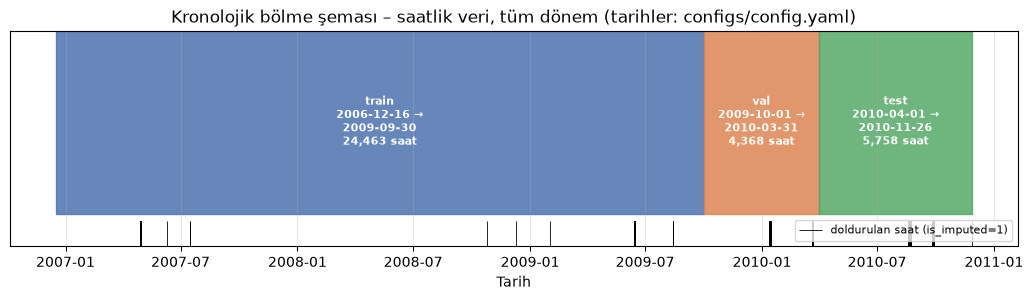

In [9]:
colors = {"train": "#4C72B0", "val": "#DD8452", "test": "#55A868"}
fig, ax = plt.subplots(figsize=(13, 2.8))
for name, part in splits.items():
    start, end = part.index.min(), part.index.max()
    ax.axvspan(start, end, ymin=0.15, ymax=1, color=colors[name], alpha=0.85)
    ax.text(
        start + (end - start) / 2, 0.58,
        f"{name}\n{start:%Y-%m-%d} →\n{end:%Y-%m-%d}\n{len(part):,} saat",
        ha="center", va="center", color="white", fontsize=8, fontweight="bold",
    )
# Doldurulan saatlerin konumu (değer değil, yalnızca yer) alt şeritte
imputed_times = hourly.index[hourly["is_imputed"] == 1]
ax.vlines(imputed_times, 0, 0.12, color="black", linewidth=0.6, label="doldurulan saat (is_imputed=1)")
ax.set_ylim(0, 1)
ax.set_yticks([])
ax.set_xlabel("Tarih")
ax.set_title("Kronolojik bölme şeması – saatlik veri, tüm dönem (tarihler: configs/config.yaml)")
ax.legend(loc="lower right", fontsize=8)
save_fig(fig, "split_scheme")
plt.show()

**Gözlem:** Bölme: train 24.463 saat (%70,7), val 4.368 saat (%12,6), test 5.758 saat (%16,6); kümelerin toplamı tüm saatlere (34.589) eşit. Doldurulan saatler train'de 138, val'de 86, test'te 208. Test, train'in yaklaşık dörtte biri uzunluğunda olmasına rağmen en çok doldurulan saati içeriyor (2010 Ağustos–Eylül kesintileri). Doldurulmuş hedef içeren pencereler metrikten çıkarıldığı için test'te değerlendirilen pencere sayısı bundan etkilenecek.

In [10]:
# Bundan sonraki tüm analizler YALNIZ eğitim kümesi üzerinde.
train = splits["train"]
observed = train[train["is_imputed"] == 0]     # doldurulmuş saatler istatistiğe katılmaz
TRAIN_LABEL = f"eğitim kümesi ({train.index.min():%Y-%m-%d} – {train.index.max():%Y-%m-%d})"

del hourly, splits
gc.collect()
print(TRAIN_LABEL)
print(f"Eğitim saatleri: {len(train):,} | gözlenen (doldurulmamış): {len(observed):,}")

eğitim kümesi (2006-12-16 – 2009-09-30)
Eğitim saatleri: 24,463 | gözlenen (doldurulmamış): 24,325


## 4. Tanımlayıcı istatistikler ve histogramlar (eğitim kümesi, gözlenen saatler)

In [11]:
NUM_COLS = [
    TARGET, "Global_reactive_power", "Voltage", "Global_intensity",
    "Sub_metering_1", "Sub_metering_2", "Sub_metering_3", "other_energy",
]
UNITS = {
    TARGET: "kW, saatlik ort.",
    "Global_reactive_power": "kW, saatlik ort.",
    "Voltage": "V, saatlik ort.",
    "Global_intensity": "A, saatlik ort.",
    "Sub_metering_1": "Wh, saatlik toplam",
    "Sub_metering_2": "Wh, saatlik toplam",
    "Sub_metering_3": "Wh, saatlik toplam",
    "other_energy": "Wh, saatlik toplam",
}

stats = observed[NUM_COLS].astype("float64").describe().T
stats["skewness"] = observed[NUM_COLS].astype("float64").skew()
stats["unit"] = [UNITS[c] for c in NUM_COLS]
print(stats.round(3).to_string())

                         count     mean      std      min      25%      50%      75%       max  skewness                unit
Global_active_power    24325.0    1.086    0.927    0.124    0.323    0.765    1.577     6.561     1.343    kW, saatlik ort.
Global_reactive_power  24325.0    0.121    0.067    0.021    0.076    0.104    0.146     0.774     1.941    kW, saatlik ort.
Voltage                24325.0  240.494    3.041  225.835  238.808  240.708  242.439   251.902    -0.411     V, saatlik ort.
Global_intensity       24325.0    4.616    3.886    0.503    1.440    3.300    6.613    28.383     1.392     A, saatlik ort.
Sub_metering_1         24325.0   68.838  215.742    0.000    0.000    0.000    0.000  2902.000     4.149  Wh, saatlik toplam
Sub_metering_2         24325.0   82.064  263.408    0.000    0.000   20.000   37.000  2786.000     5.076  Wh, saatlik toplam
Sub_metering_3         24325.0  364.777  433.806    0.000    0.000   96.000  791.000  1227.000     0.755  Wh, saatlik toplam


Kaydedildi: results\figures\eda_hist_target.png


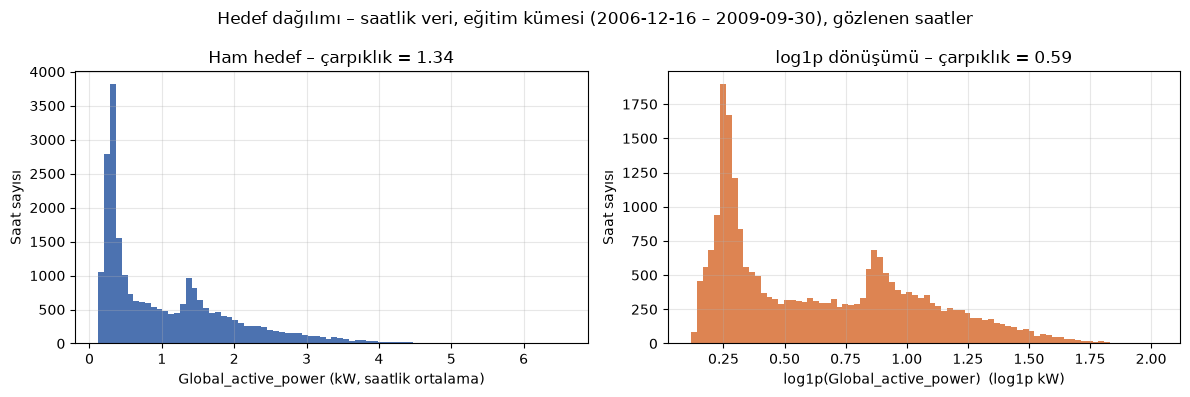

In [12]:
y = observed[TARGET].astype("float64")
log_y = np.log1p(y)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(y, bins=80, color="#4C72B0")
axes[0].set_title(f"Ham hedef – çarpıklık = {y.skew():.2f}")
axes[0].set_xlabel("Global_active_power (kW, saatlik ortalama)")
axes[0].set_ylabel("Saat sayısı")
axes[1].hist(log_y, bins=80, color="#DD8452")
axes[1].set_title(f"log1p dönüşümü – çarpıklık = {log_y.skew():.2f}")
axes[1].set_xlabel("log1p(Global_active_power)  (log1p kW)")
axes[1].set_ylabel("Saat sayısı")
fig.suptitle(f"Hedef dağılımı – saatlik veri, {TRAIN_LABEL}, gözlenen saatler")
fig.tight_layout()
save_fig(fig, "hist_target")
plt.show()

**Gözlem:** Saatlik hedef sağa çarpık (çarpıklık 1,34). En yoğun bölge yaklaşık 0,3 kW civarında, yaklaşık 1,4 kW civarında da ikinci bir tepe var; dağılım iki tepeli. log1p dönüşümü çarpıklığı 0,59'a düşürüyor ama iki tepeli yapı kalıyor. Çarpıklık orta düzeyde olduğundan log1p'nin gerekli olup olmadığı bu figürle kesinleşmiyor; config'te şimdilik `log1p_target: false`.

Kaydedildi: results\figures\eda_hist_features.png


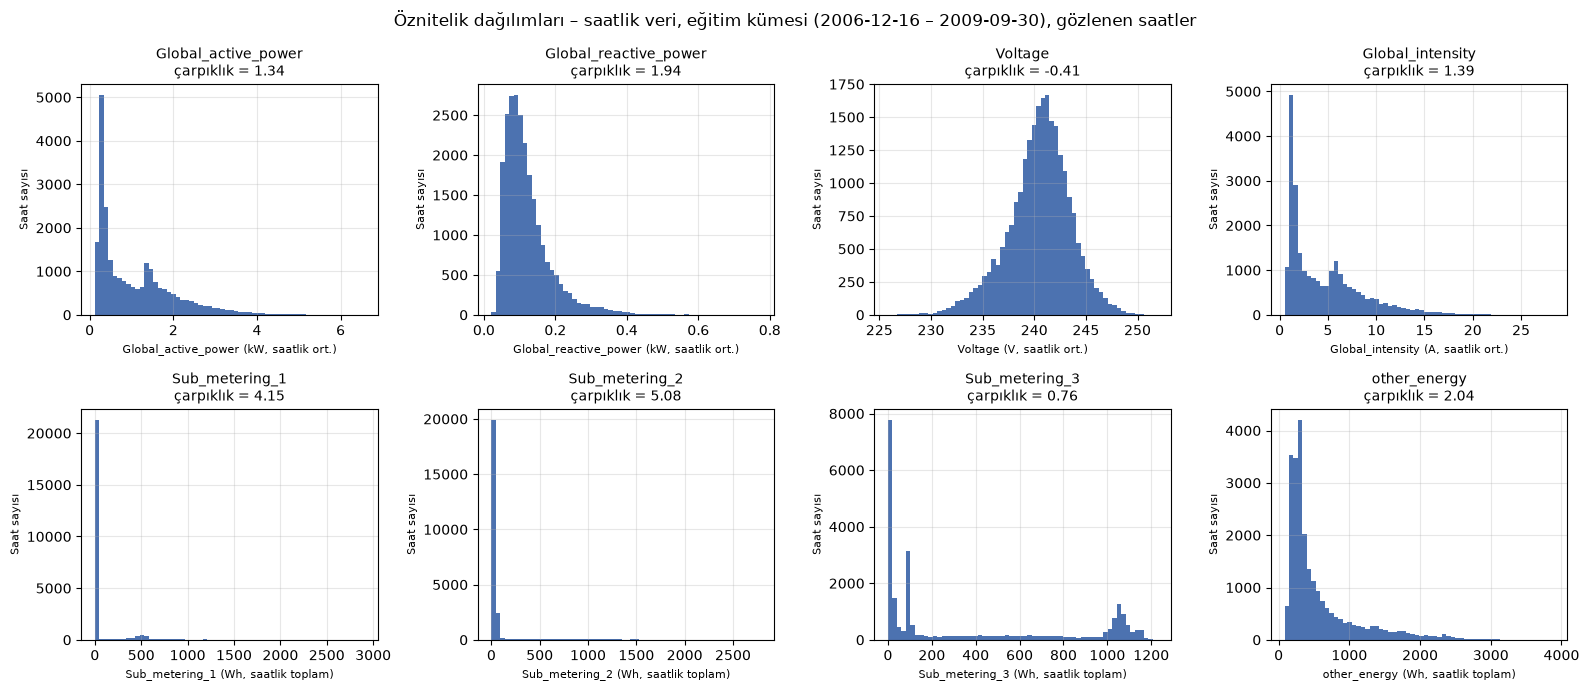

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), NUM_COLS):
    values = observed[col].astype("float64")
    ax.hist(values, bins=60, color="#4C72B0")
    ax.set_title(f"{col}\nçarpıklık = {values.skew():.2f}", fontsize=10)
    ax.set_xlabel(f"{col} ({UNITS[col]})", fontsize=8)
    ax.set_ylabel("Saat sayısı", fontsize=8)
fig.suptitle(f"Öznitelik dağılımları – saatlik veri, {TRAIN_LABEL}, gözlenen saatler")
fig.tight_layout()
save_fig(fig, "hist_features")
plt.show()

**Gözlem:** Voltage yaklaşık simetrik (çarpıklık −0,41) ve ortalaması 240,5 V. Sub_metering_1 ve Sub_metering_2 çok çarpık (4,15 ve 5,08): Sub_metering_1'in medyanı ve 75. yüzdeliği 0 Wh, yani saatlerin çoğunda mutfak sayacı ölçüm göstermiyor. Sub_metering_3'te 0, yaklaşık 100 Wh ve yaklaşık 1.000–1.100 Wh civarında üç ayrı yığılma var. Global_intensity'nin histogramı hedefinkiyle neredeyse aynı biçimde.

## 5. Zaman örüntüleri: günlük, haftalık, aylık profil (eğitim kümesi)

Kaydedildi: results\figures\eda_daily_profile.png


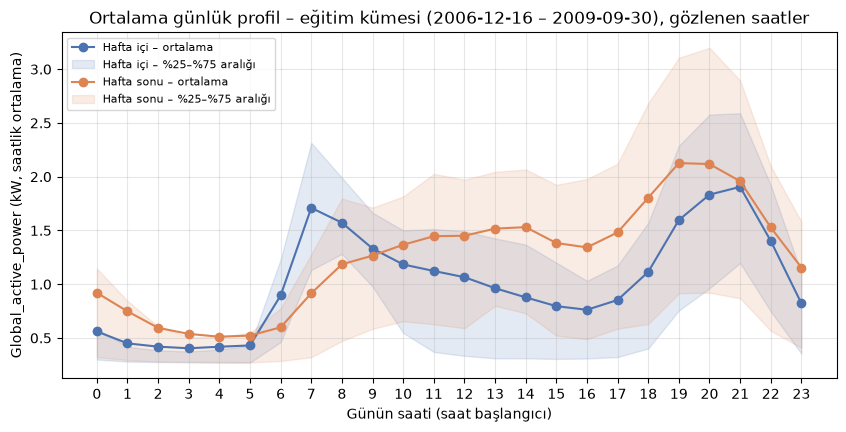

Hafta içi: en yüksek saat 21 (1.905 kW), en düşük saat 3 (0.404 kW), günlük ortalama 1.021 kW
Hafta sonu: en yüksek saat 19 (2.127 kW), en düşük saat 4 (0.512 kW), günlük ortalama 1.251 kW


In [14]:
fig, ax = plt.subplots(figsize=(10, 4.5))
profile_rows = {}
for label, mask, color in [
    ("Hafta içi", observed["is_weekend"] == 0, "#4C72B0"),
    ("Hafta sonu", observed["is_weekend"] == 1, "#DD8452"),
]:
    part = observed.loc[mask, TARGET]
    grouped = part.groupby(part.index.hour)
    mean = grouped.mean()
    profile_rows[label] = mean
    ax.plot(mean.index, mean.to_numpy(), marker="o", color=color, label=f"{label} – ortalama")
    ax.fill_between(mean.index, grouped.quantile(0.25), grouped.quantile(0.75),
                    color=color, alpha=0.15, label=f"{label} – %25–%75 aralığı")
ax.set_xticks(range(0, 24))
ax.set_xlabel("Günün saati (saat başlangıcı)")
ax.set_ylabel("Global_active_power (kW, saatlik ortalama)")
ax.set_title(f"Ortalama günlük profil – {TRAIN_LABEL}, gözlenen saatler")
ax.legend(fontsize=8)
save_fig(fig, "daily_profile")
plt.show()

profile = pd.DataFrame(profile_rows)
for col in profile.columns:
    print(f"{col}: en yüksek saat {profile[col].idxmax()} ({profile[col].max():.3f} kW), "
          f"en düşük saat {profile[col].idxmin()} ({profile[col].min():.3f} kW), "
          f"günlük ortalama {observed.loc[observed['is_weekend'] == (col == 'Hafta sonu'), TARGET].mean():.3f} kW")

**Gözlem:** Hafta içinde iki tepe var: sabah 07:00 (yaklaşık 1,7 kW) ve akşam 21:00 (1,905 kW); en düşük değer gece 03:00'te (0,404 kW). Hafta sonunda sabah tepesi yok, tüketim gün ortasında 1,2–1,5 kW bandında kalıyor ve tepe 19:00'da (2,127 kW). Ortalama tüketim hafta sonu 1,251 kW, hafta içi 1,021 kW. %25–%75 bantları en geniş akşam saatlerinde.

Kaydedildi: results\figures\eda_weekly_profile.png


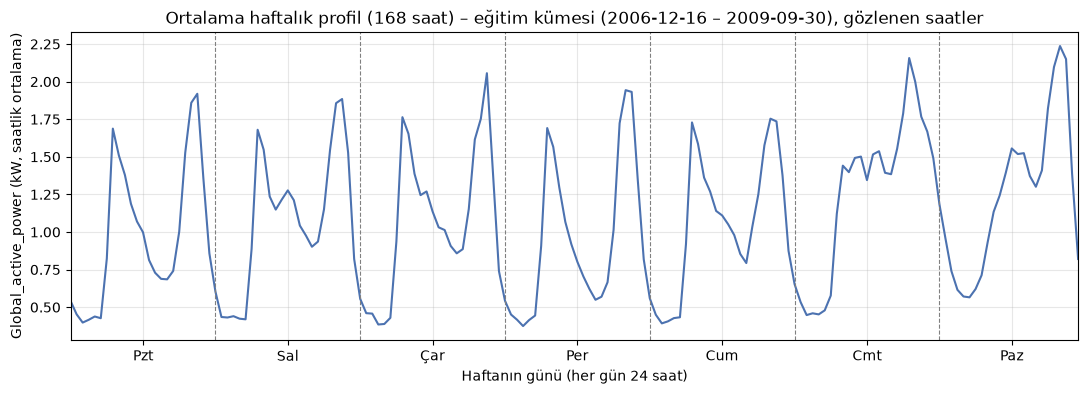

Günlere göre ortalama (kW):
Pzt    0.981
Sal    1.067
Çar    1.062
Per    0.949
Cum    1.044
Cmt    1.257
Paz    1.244


In [15]:
# Haftanın saati: Pazartesi 00:00 = 0, Pazar 23:00 = 167
hour_of_week = observed.index.dayofweek * 24 + observed.index.hour
weekly = observed[TARGET].groupby(hour_of_week).mean()

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(weekly.index, weekly.to_numpy(), color="#4C72B0")
for d in range(1, 7):
    ax.axvline(d * 24, color="grey", linewidth=0.8, linestyle="--")
ax.set_xticks([d * 24 + 12 for d in range(7)], DAY_NAMES)
ax.set_xlim(0, 167)
ax.set_xlabel("Haftanın günü (her gün 24 saat)")
ax.set_ylabel("Global_active_power (kW, saatlik ortalama)")
ax.set_title(f"Ortalama haftalık profil (168 saat) – {TRAIN_LABEL}, gözlenen saatler")
save_fig(fig, "weekly_profile")
plt.show()

by_day = observed[TARGET].groupby(observed.index.dayofweek).mean()
by_day.index = DAY_NAMES
print("Günlere göre ortalama (kW):")
print(by_day.round(3).to_string())

**Gözlem:** İki tepeli günlük desen her gün tekrar ediyor. Pazartesi–Cuma birbirine benziyor; Cumartesi ve Pazar farklı (sabah tepesi yok, gün ortası yüksek). Günlük ortalamalar Pzt 0,981, Sal 1,067, Çar 1,062, Per 0,949, Cum 1,044, Cmt 1,257, Paz 1,244 kW. Haftanın en yüksek saati Pazar 20:00 (2,236 kW).

Kaydedildi: results\figures\eda_monthly_trend.png


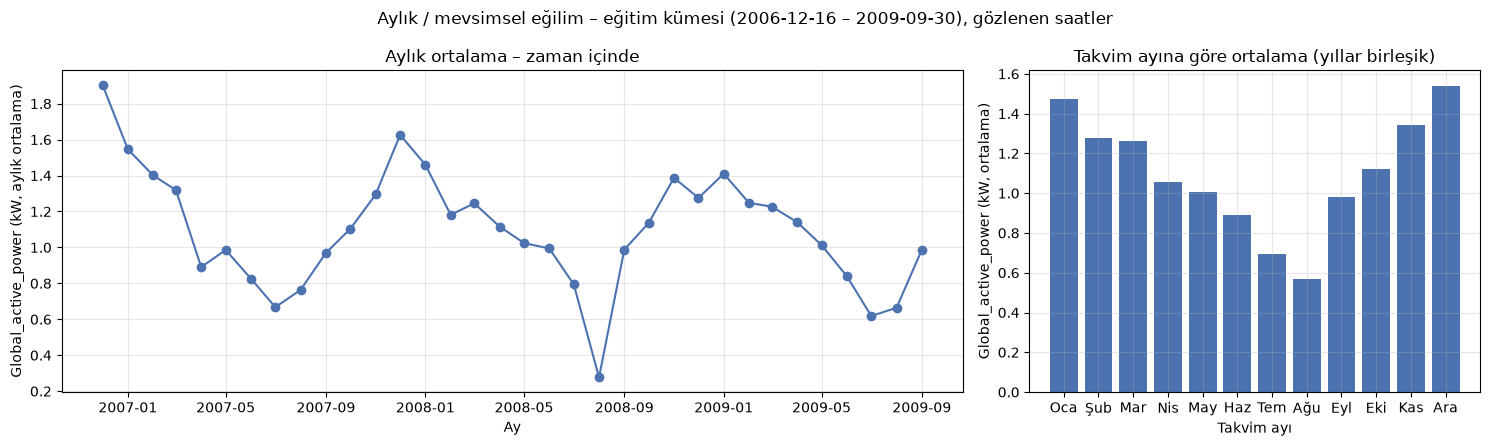

Takvim ayına göre ortalama (kW):
Oca    1.472
Şub    1.276
Mar    1.264
Nis    1.054
May    1.008
Haz    0.888
Tem    0.693
Ağu    0.568
Eyl    0.981
Eki    1.120
Kas    1.341
Ara    1.541

En az gözlenen saat içeren 3 ay:
datetime
2006-12-01    367
2007-04-01    658
2009-06-01    665


In [16]:
monthly = observed[TARGET].resample("MS").mean()
monthly_hours = observed[TARGET].resample("MS").size()
by_month = observed[TARGET].groupby(observed.index.month).mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(monthly.index, monthly.to_numpy(), marker="o", color="#4C72B0")
axes[0].set_xlabel("Ay")
axes[0].set_ylabel("Global_active_power (kW, aylık ortalama)")
axes[0].set_title("Aylık ortalama – zaman içinde")
axes[1].bar(range(1, 13), by_month.to_numpy(), color="#4C72B0")
axes[1].set_xticks(range(1, 13), MONTH_NAMES)
axes[1].set_xlabel("Takvim ayı")
axes[1].set_ylabel("Global_active_power (kW, ortalama)")
axes[1].set_title("Takvim ayına göre ortalama (yıllar birleşik)")
fig.suptitle(f"Aylık / mevsimsel eğilim – {TRAIN_LABEL}, gözlenen saatler")
fig.tight_layout()
save_fig(fig, "monthly_trend")
plt.show()

print("Takvim ayına göre ortalama (kW):")
print(pd.Series(by_month.to_numpy(), index=MONTH_NAMES).round(3).to_string())
print("\nEn az gözlenen saat içeren 3 ay:")
print(monthly_hours.nsmallest(3).to_string())

**Gözlem:** Takvim ayına göre en yüksek ortalamalar Aralık (1,541 kW) ve Ocak (1,472 kW), en düşükler Ağustos (0,568 kW) ve Temmuz (0,693 kW); kışın yüksek, yazın düşük bir mevsimsellik var. Zaman serisinde Ağustos 2008 yaklaşık 0,27 kW ile belirgin bir çukur oluşturuyor. Aralık 2006 yalnızca 367 gözlenen saat içeriyor (veri 16 Aralık'ta başlıyor) ve grafikteki en yüksek aylık değer (yaklaşık 1,9 kW) bu ay. Not: val dönemi Ekim–Mart, test dönemi ise Nisan–Kasım; bu figüre göre iki dönem farklı mevsim düzeylerine denk geliyor.

Kaydedildi: results\figures\eda_heatmap_hour_dow.png


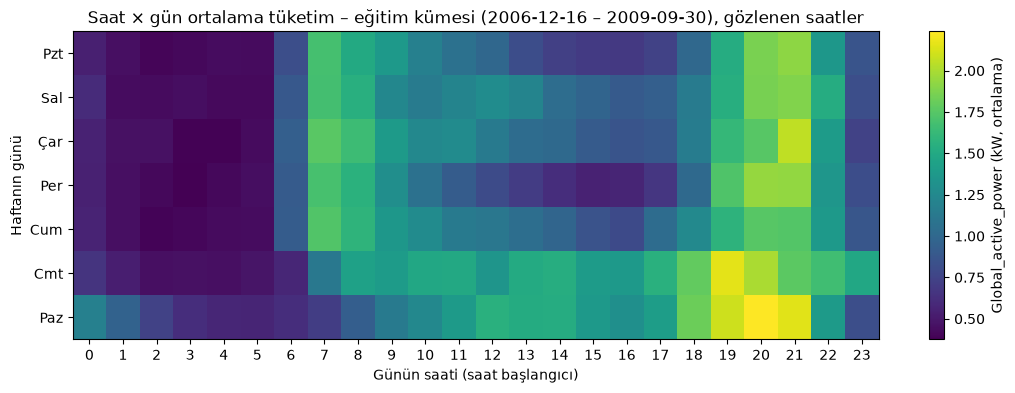

En yüksek 3 hücre (kW):
Paz 20:00    2.236
Cmt 19:00    2.157
Paz 21:00    2.150
En düşük 3 hücre (kW):
Per 03:00    0.375
Çar 03:00    0.385
Çar 04:00    0.388


In [17]:
heat = observed[TARGET].groupby([observed.index.dayofweek, observed.index.hour]).mean().unstack()

fig, ax = plt.subplots(figsize=(13, 4))
im = ax.imshow(heat.to_numpy(), aspect="auto", cmap="viridis")
ax.set_yticks(range(7), DAY_NAMES)
ax.set_xticks(range(24))
ax.grid(False)
ax.set_xlabel("Günün saati (saat başlangıcı)")
ax.set_ylabel("Haftanın günü")
ax.set_title(f"Saat × gün ortalama tüketim – {TRAIN_LABEL}, gözlenen saatler")
fig.colorbar(im, ax=ax, label="Global_active_power (kW, ortalama)")
save_fig(fig, "heatmap_hour_dow")
plt.show()

stacked = heat.stack()
stacked.index = [f"{DAY_NAMES[day]} {hour:02d}:00" for day, hour in stacked.index]
print("En yüksek 3 hücre (kW):")
print(stacked.nlargest(3).round(3).to_string())
print("En düşük 3 hücre (kW):")
print(stacked.nsmallest(3).round(3).to_string())

**Gözlem:** En yüksek hücreler hafta sonu akşamlarında: Paz 20:00 (2,236 kW), Cmt 19:00 (2,157 kW), Paz 21:00 (2,150 kW). En düşük hücreler hafta içi gece 03:00–04:00'te (Per 03:00: 0,375 kW). Hafta içi günlerde 07:00 sütunu açık renkli, Cumartesi ve Pazar'da koyu. Pazar 00:00, diğer günlerin aynı saatinden daha açık renkli.

## 6. Alt sayaç payları (eğitim kümesi, gözlenen saatler)

Toplam aktif enerji: 26.4 MWh
                 MWh  pay_%
Sub_metering_1   1.7    6.3
Sub_metering_2   2.0    7.6
Sub_metering_3   8.9   33.6
other_energy    13.9   52.5
Payların toplamı: %100.00


Kaydedildi: results\figures\eda_submetering_shares.png


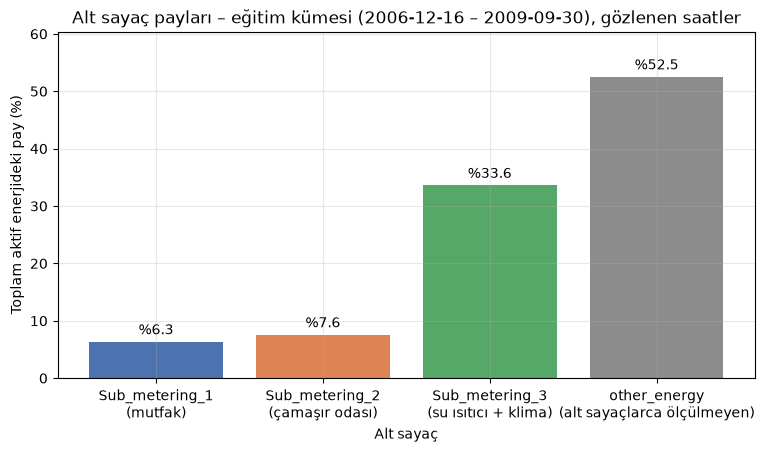

In [18]:
# Saatlik ortalama kW × 1 saat × 1000 = o saatte tüketilen Wh
total_wh = (observed[TARGET].astype("float64") * 1000).sum()
meter_labels = {
    "Sub_metering_1": "Sub_metering_1\n(mutfak)",
    "Sub_metering_2": "Sub_metering_2\n(çamaşır odası)",
    "Sub_metering_3": "Sub_metering_3\n(su ısıtıcı + klima)",
    "other_energy": "other_energy\n(alt sayaçlarca ölçülmeyen)",
}
meter_wh = pd.Series({c: observed[c].astype("float64").sum() for c in meter_labels})
share_pct = meter_wh / total_wh * 100

print(f"Toplam aktif enerji: {total_wh / 1e6:,.1f} MWh")
print((pd.DataFrame({"MWh": (meter_wh / 1e6).round(1), "pay_%": share_pct.round(1)})).to_string())
# other_energy = toplam − alt sayaçlar olarak türetildiği için toplam %100 olmalı (tutarlılık kontrolü)
print(f"Payların toplamı: %{share_pct.sum():.2f}")

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar([meter_labels[c] for c in share_pct.index], share_pct.to_numpy(),
              color=["#4C72B0", "#DD8452", "#55A868", "#8C8C8C"])
ax.bar_label(bars, labels=[f"%{v:.1f}" for v in share_pct], padding=3)
ax.set_ylabel("Toplam aktif enerjideki pay (%)")
ax.set_xlabel("Alt sayaç")
ax.set_ylim(0, share_pct.max() * 1.15)
ax.set_title(f"Alt sayaç payları – {TRAIN_LABEL}, gözlenen saatler")
save_fig(fig, "submetering_shares")
plt.show()

**Gözlem:** Eğitim dönemindeki 26,4 MWh aktif enerjinin %52,5'i hiçbir alt sayaçla ölçülmüyor (other_energy). Alt sayaçlar içinde en büyük payı su ısıtıcı + klima alıyor (%33,6); mutfak %6,3, çamaşır odası %7,6. other_energy toplamdan türetildiği için paylar tanım gereği %100'e tamamlanıyor.

## 7. Korelasyon (eğitim kümesi, gözlenen saatler)

Kaydedildi: results\figures\eda_corr_matrix.png


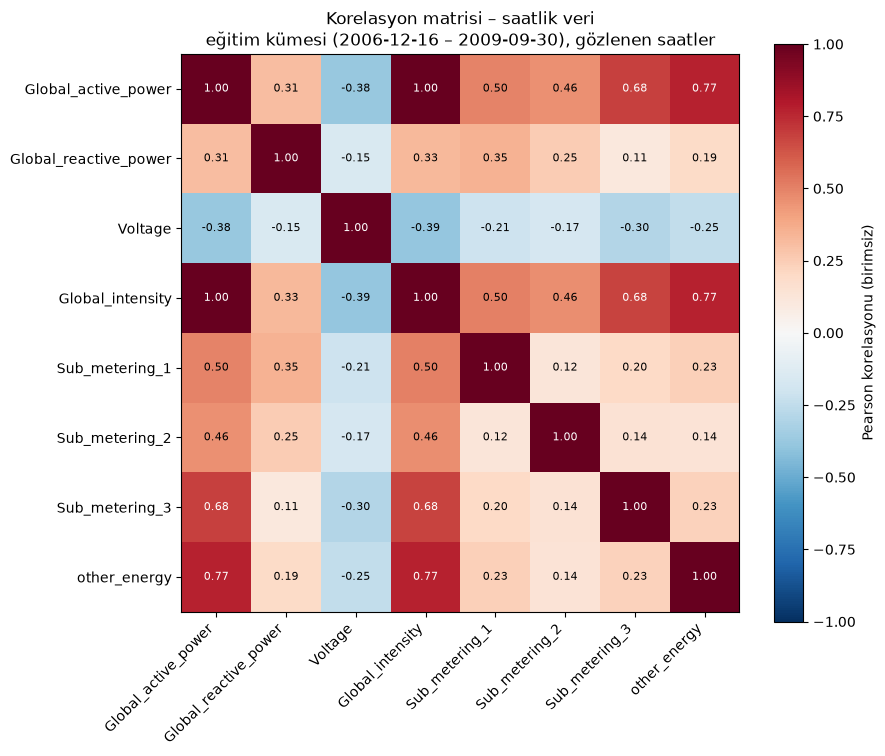

Hedefle korelasyonlar (büyükten küçüğe):
Global_intensity         0.999
other_energy             0.767
Sub_metering_3           0.685
Sub_metering_1           0.496
Sub_metering_2           0.456
Global_reactive_power    0.310
Voltage                 -0.375


In [19]:
corr = observed[NUM_COLS].astype("float64").corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUM_COLS)), NUM_COLS, rotation=45, ha="right")
ax.set_yticks(range(len(NUM_COLS)), NUM_COLS)
ax.grid(False)
for i in range(len(NUM_COLS)):
    for j in range(len(NUM_COLS)):
        value = corr.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                color="white" if abs(value) > 0.6 else "black", fontsize=8)
fig.colorbar(im, ax=ax, label="Pearson korelasyonu (birimsiz)")
ax.set_title(f"Korelasyon matrisi – saatlik veri\n{TRAIN_LABEL}, gözlenen saatler")
save_fig(fig, "corr_matrix")
plt.show()

print("Hedefle korelasyonlar (büyükten küçüğe):")
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3).to_string())

**Gözlem:** Hedefle en yüksek korelasyon Global_intensity'de (0,999), ardından other_energy (0,767) ve Sub_metering_3 (0,685) geliyor. Voltage hedefle negatif ilişkili (−0,375). Alt sayaçların kendi aralarındaki korelasyonlar düşük (0,12–0,23).

Kaydedildi: results\figures\eda_power_vs_intensity.png


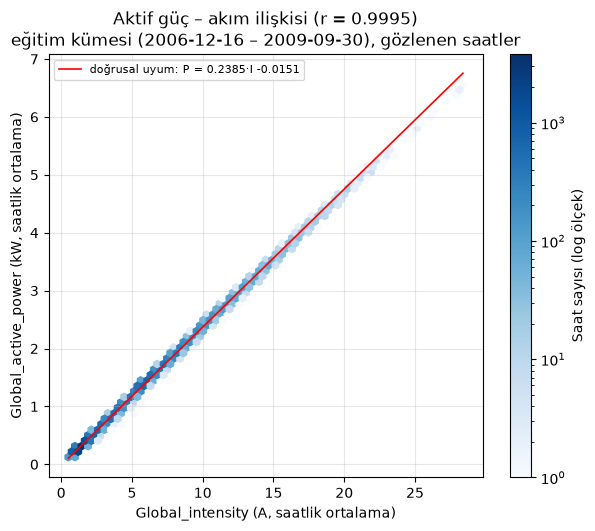

Pearson r = 0.9995, r² = 0.9990
Eğim = 0.23849 kW/A = 238.5 W/A
Ortalama voltaj = 240.5 V


In [20]:
intensity = observed["Global_intensity"].astype("float64")
power = observed[TARGET].astype("float64")
r = power.corr(intensity)
slope, intercept = np.polyfit(intensity, power, 1)   # power ≈ slope * intensity + intercept

fig, ax = plt.subplots(figsize=(7, 5.5))
hb = ax.hexbin(intensity, power, gridsize=60, bins="log", cmap="Blues", mincnt=1)
x_line = np.array([intensity.min(), intensity.max()])
ax.plot(x_line, slope * x_line + intercept, color="red", linewidth=1.2,
        label=f"doğrusal uyum: P = {slope:.4f}·I {intercept:+.4f}")
ax.set_xlabel("Global_intensity (A, saatlik ortalama)")
ax.set_ylabel("Global_active_power (kW, saatlik ortalama)")
ax.set_title(f"Aktif güç – akım ilişkisi (r = {r:.4f})\n{TRAIN_LABEL}, gözlenen saatler")
ax.legend(fontsize=8)
fig.colorbar(hb, ax=ax, label="Saat sayısı (log ölçek)")
save_fig(fig, "power_vs_intensity")
plt.show()

print(f"Pearson r = {r:.4f}, r² = {r**2:.4f}")
print(f"Eğim = {slope:.5f} kW/A = {slope * 1000:.1f} W/A")
print(f"Ortalama voltaj = {observed['Voltage'].mean():.1f} V")

**Gözlem:** r = 0,9995 (r² = 0,9990); noktalar neredeyse tek bir doğru üzerinde. Doğrunun eğimi 238,5 W/A ve ortalama voltaja (240,5 V) çok yakın, bu da P ≈ V·I ilişkisiyle uyumlu. Bu çıktıya göre Global_intensity hedefe ek bilgi taşımıyor; öznitelik seti C'ye alınmama kararı bu sonuçla destekleniyor.

## 8. Otokorelasyon (ACF) – eğitim kümesi

ACF kesintisiz bir seri ister; bu yüzden burada doldurulmuş saatler de dahildir (oranı aşağıda yazdırılır).
400 gecikmeye kadar bakıyoruz: 24 (bir gün), 168 (bir hafta) ve 336 (iki hafta) görünsün.

Seri uzunluğu: 24,463 saat | doldurulmuş saat oranı: %0.56


Kaydedildi:

 results\figures\eda_acf.png


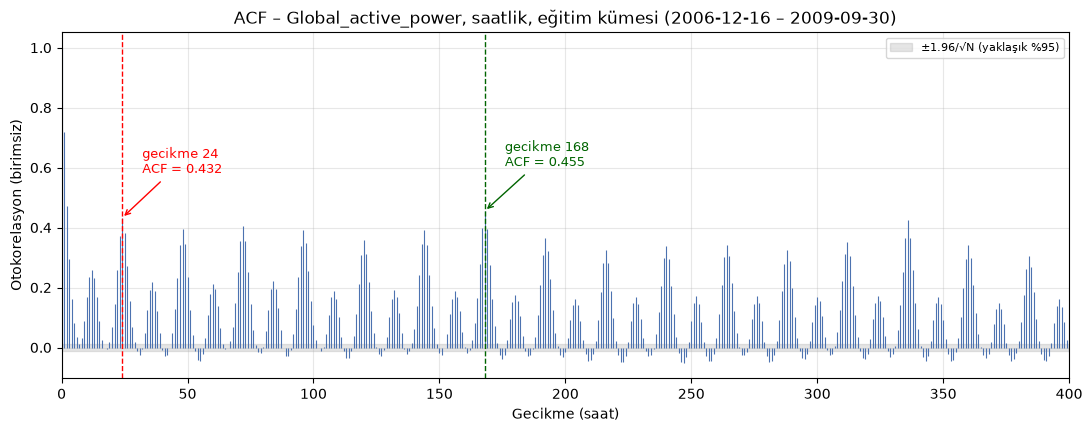

1      0.719
2      0.473
12     0.259
24     0.432
48     0.395
72     0.405
144    0.391
167    0.398
168    0.455
169    0.394
336    0.425


In [21]:
series = train[TARGET].astype("float64")
print(f"Seri uzunluğu: {len(series):,} saat | doldurulmuş saat oranı: %{train['is_imputed'].mean() * 100:.2f}")

N_LAGS = 400
acf_values = acf(series, nlags=N_LAGS, fft=True)
conf = 1.96 / np.sqrt(len(series))   # beyaz gürültü için yaklaşık %95 sınırı

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.vlines(range(N_LAGS + 1), 0, acf_values, color="#4C72B0", linewidth=0.8)
ax.axhspan(-conf, conf, color="grey", alpha=0.2, label="±1.96/√N (yaklaşık %95)")
for lag, color in [(24, "red"), (168, "darkgreen")]:
    ax.axvline(lag, color=color, linestyle="--", linewidth=1)
    ax.annotate(f"gecikme {lag}\nACF = {acf_values[lag]:.3f}", xy=(lag, acf_values[lag]),
                xytext=(lag + 8, acf_values[lag] + 0.15), color=color, fontsize=9,
                arrowprops={"arrowstyle": "->", "color": color})
ax.set_xlim(0, N_LAGS)
ax.set_xlabel("Gecikme (saat)")
ax.set_ylabel("Otokorelasyon (birimsiz)")
ax.set_title(f"ACF – Global_active_power, saatlik, {TRAIN_LABEL}")
ax.legend(loc="upper right", fontsize=8)
save_fig(fig, "acf")
plt.show()

key_lags = [1, 2, 12, 24, 48, 72, 144, 167, 168, 169, 336]
print(pd.Series(acf_values[key_lags], index=key_lags, name="ACF").round(3).to_string())

**Gözlem:** Gecikme 1'de ACF 0,719. 24'ün katlarında tepeler görülüyor: 24 → 0,432, 48 → 0,395, 72 → 0,405. Gecikme 168'deki değer (0,455) komşularından (167: 0,398, 169: 0,394) yüksek ve gecikme 2'den sonra 400'e kadarki en yüksek tepe; 336'da da 0,425 ile bir tepe var. Tepeler 400 gecikmeye kadar sönmeden sürüyor. Bu çıktı, hem günlük (24) hem haftalık (168) döngüyü kapsayan 168 saatlik lookback seçimini destekliyor.

## 9. Olağandışı dönemler: günlük toplam tüketimi en düşük ve en yüksek 10 gün (eğitim kümesi)

Günlük toplam = o günün 24 saatlik ortalama kW değerlerinin toplamı (kWh). Yalnızca **24 saatin tamamı gözlenmiş** (doldurulmamış) günler kullanılır; aksi halde doldurma değerleri sıralamayı etkiler.

In [22]:
daily_kwh = train[TARGET].astype("float64").resample("1D").sum()      # kW × 1 saat = kWh
observed_hours = (train["is_imputed"] == 0).resample("1D").sum()
daily_holiday = train["is_holiday"].resample("1D").max()
complete = daily_kwh[observed_hours == 24]
print(f"Eğitim günleri: {len(daily_kwh)} | 24 saati tam gözlenen: {len(complete)} | "
      f"dışarıda kalan: {len(daily_kwh) - len(complete)}")
print(f"Günlük toplam: ortalama {complete.mean():.2f} kWh, medyan {complete.median():.2f} kWh")


def day_table(days):
    """Seçilen günleri tarih, gün adı, toplam kWh ve tatil bilgisiyle tablolaştırır."""
    return pd.DataFrame({
        "tarih": days.index.strftime("%Y-%m-%d"),
        "gün": [DAY_NAMES[d] for d in days.index.dayofweek],
        "toplam_kWh": days.round(2).to_numpy(),
        "resmi_tatil": daily_holiday.loc[days.index].astype(int).to_numpy(),
    })


lowest = complete.nsmallest(10)
highest = complete.nlargest(10)
print("\nEn düşük 10 gün:")
print(day_table(lowest).to_string(index=False))
print("\nEn yüksek 10 gün:")
print(day_table(highest).to_string(index=False))

Eğitim günleri: 1020 | 24 saati tam gözlenen: 1007 | dışarıda kalan: 13
Günlük toplam: ortalama 26.06 kWh, medyan 25.51 kWh

En düşük 10 gün:
     tarih gün  toplam_kWh  resmi_tatil
2008-08-25 Pzt        4.17            0
2008-08-23 Cmt        4.24            0
2008-08-24 Paz        4.25            0
2008-08-26 Sal        4.29            0
2008-08-27 Çar        4.30            0
2008-08-21 Per        4.35            0
2008-08-22 Cum        4.45            0
2008-08-29 Cum        4.46            0
2008-08-28 Per        4.47            0
2008-08-20 Çar        4.47            0

En yüksek 10 gün:
     tarih gün  toplam_kWh  resmi_tatil
2006-12-23 Cmt       79.56            0
2007-02-03 Cmt       67.16            0
2006-12-26 Sal       65.57            0
2007-02-18 Paz       63.83            0
2007-02-04 Paz       59.93            0
2007-02-11 Paz       59.52            0
2007-03-31 Cmt       58.49            0
2006-12-31 Paz       58.24            0
2007-03-11 Paz       58.01            0

Kaydedildi: results\figures\eda_daily_extremes.png


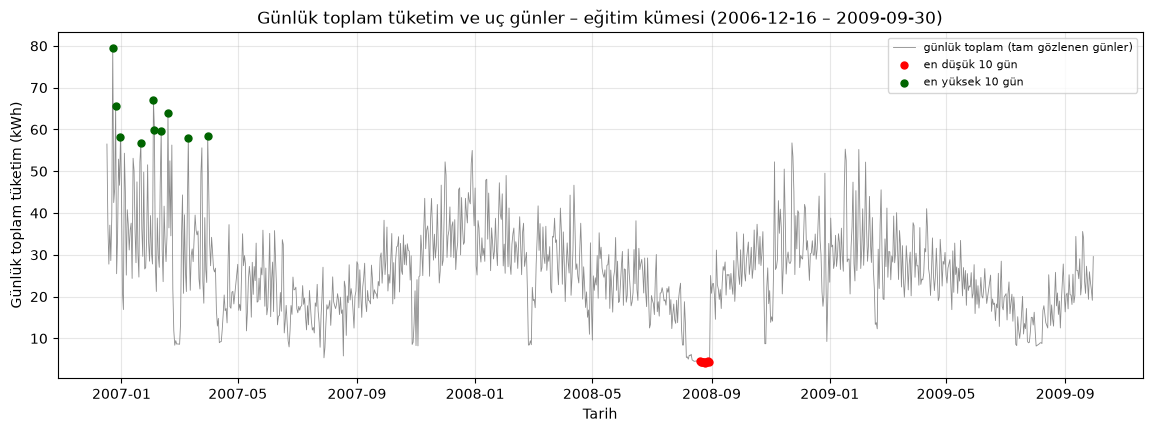

In [23]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(complete.index, complete.to_numpy(), color="#8C8C8C", linewidth=0.6, label="günlük toplam (tam gözlenen günler)")
ax.scatter(lowest.index, lowest.to_numpy(), color="red", zorder=3, s=25, label="en düşük 10 gün")
ax.scatter(highest.index, highest.to_numpy(), color="darkgreen", zorder=3, s=25, label="en yüksek 10 gün")
ax.set_xlabel("Tarih")
ax.set_ylabel("Günlük toplam tüketim (kWh)")
ax.set_title(f"Günlük toplam tüketim ve uç günler – {TRAIN_LABEL}")
ax.legend(fontsize=8)
save_fig(fig, "daily_extremes")
plt.show()

**Gözlem:** En düşük 10 günün hepsi tek bir ardışık dönemde: 2008-08-20 → 2008-08-29 (4,17–4,47 kWh; tam gözlenen günlerin medyanı 25,51 kWh). En yüksek 10 günün hepsi Aralık 2006 – Mart 2007 arasında ve 9'u Cumartesi ya da Pazar; en yüksek gün 2006-12-23 (79,56 kWh). Hiçbiri resmi tatil olarak işaretli değil. 13 gün eksik saat içerdiği için sıralamaya alınmadı. Ağustos 2008 dönemi eğitim kümesinin içinde, yani LSTM-AE bu deseni 'normal' veri olarak görecek (README §4.6'daki kontaminasyon sınırlılığı).

## 10. Özet

Sayılar yukarıdaki hücre çıktılarından alınmıştır. Değer içeren analizler yalnız eğitim kümesinde (2006-12-16 – 2009-09-30) yapılmıştır.

1. **Eksik veri:** Dakikalarının %1,252'si eksik (25.979 dk), tüm sütunlar aynı dakikalarda eksik. Eksik sürenin %94,9'u, 24 saatten uzun 6 kesintiden geliyor. Saatlikte 432 saat dolduruldu: train 138, val 86, test 208.
2. **Periyodiklik:** ACF tepeleri 24 (0,432) ve 168'de (0,455); 168, gecikme 2'den sonraki en yüksek tepe. Bu, 168 → 24 pencere tasarımını destekliyor.
3. **Hafta içi / sonu farkı:** Hafta içinde 07:00 ve 21:00'de iki tepe var, hafta sonunda sabah tepesi yok ve ortalama tüketim daha yüksek (1,251 / 1,021 kW). Bu, takvim özniteliklerinin (öznitelik seti B) gerekçesi.
4. **Mevsimsellik:** Aralık ortalaması 1,541 kW, Ağustos ortalaması 0,568 kW. Val dönemi kışa (Ekim–Mart), test dönemi yaz ağırlıklı aylara (Nisan–Kasım) denk geliyor.
5. **Dağılım:** Hedef sağa çarpık (1,34) ve iki tepeli; log1p çarpıklığı 0,59'a düşürüyor. Karar şimdilik açık.
6. **Gereksiz öznitelik:** Global_intensity ile hedef arasında r = 0,9995 (eğim 238,5 W/A ≈ ortalama voltaj 240,5 V); C setine alınmaması destekleniyor.
7. **Olağandışı dönem:** 2008-08-20 → 2008-08-29 arasında günlük tüketim 4,2–4,5 kWh (medyan gün 25,5 kWh). Bu dönem eğitim verisinin içinde (AE kontaminasyonu).